# Drought stripes (updated version)

In [1]:
import pygrib
import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 16
#plt.rcParams["font.family"] = "Arial"
plt.rcParams['font.serif'] = ['Times New Roman']
import matplotlib.colors as colors
from matplotlib.colors import BoundaryNorm
from mpl_toolkits.basemap import Basemap
from mpl_toolkits.basemap import shiftgrid
import numpy as np
import eccodes as ec
import os
import scipy.stats as stats
import statsmodels.api as statsmodels
import datetime as dt
import pandas as pd
import geopandas as gpd
import sys
#import xclim as xclim
import calendar
import netCDF4 as nc4
import xarray as xr
import regionmask 

#sys.path.insert(0, '..')
#sys.path.insert(0, '../..')

In [2]:
# import helper functions
print(os.getcwd())
from helpers.helpers_plotting import plot_spi_timeseries, plot_precip_timeseries, create_diverging_colorscheme, plot_droughtmap#, plot_countrymap
from helpers.helpers import identify_events, count_events, sum_dict_lists, get_event_duration, count_occurrences
from helpers.geodata import calculate_gridarea, grid2df, mask_gridpoints_in_polygon, mask_3darray
from helpers.helpers_ecmwf import load_grb_file
from spidi.spidi.spidi import calculate_si
from spidi.spidi.helpers import convert_mmperday_to_mmpermonth

/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes


## Main settings

In [3]:
# settings
spi_levels = [-3, -2, -1.5, -1, -0.1, 0.1, 1, 1.5, 2, 3]
plot_type  = 'pcolormesh'
debug = True
#country = ["Somalia","Somaliland"]
#country_name = 'Somalia'
admin = ["California"]
admin_name = 'California'

In [4]:
# paths
ipath         = "/home/nejk/code/drought_on_demand/drought_stripes/data"
drought_index = "SPEI"
windows       = [1,3,6,12]
ref_period    = "1991to2020"
stream        = "moda"
ryyyy_start   = int(ref_period[:4])
ryyyy_end     = int(ref_period[6:10])
print(ryyyy_start)
print(ryyyy_end)
yyyy_start    = "1940"
yyyy_end      = "2024"
print(yyyy_start)
print(yyyy_end)

1991
2020
1940
2024


### Create color scheme

In [5]:
# create colorscheme
cmap_spi, clevels = create_diverging_colorscheme("brown_white_green", start_color = (102/255, 51/255, 0), mid_color = (1, 1, 1), end_color = (51/255, 102/255, 0), 
                                                 levels = spi_levels, levels4pcolormesh=True if plot_type == "pcolormesh" else False)
color_list = [colors.rgb2hex(cmap_spi(i)) for i in range(cmap_spi.N)]

### Handle dates

In [6]:
dates = pd.date_range(start="1940-01-01",end="2025-01-01", freq='M')
print(dates)
print(dates.size)

DatetimeIndex(['1940-01-31', '1940-02-29', '1940-03-31', '1940-04-30',
               '1940-05-31', '1940-06-30', '1940-07-31', '1940-08-31',
               '1940-09-30', '1940-10-31',
               ...
               '2024-03-31', '2024-04-30', '2024-05-31', '2024-06-30',
               '2024-07-31', '2024-08-31', '2024-09-30', '2024-10-31',
               '2024-11-30', '2024-12-31'],
              dtype='datetime64[ns]', length=1020, freq='ME')
1020


/etc/ecmwf/ssd/ssd1/ecinteractive/nejk-ecinteractive/tmpdirs/nejk.20406252/ipykernel_1596727/3646432961.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(start="1940-01-01",end="2025-01-01", freq='M')


In [7]:
pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]
print(type(pdate_seq))

<class 'list'>


## Country data

This is the simplified bit! Use regionmask's countries and functions directly

In [8]:
#regionmask.defined_regions.natural_earth.countries_110.plot(add_label=False)
#regionmask.defined_regions.natural_earth_v5_0_0.countries_110.plot(add_label=False)

<regionmask.Regions 'Natural Earth: US States 10m'>
Source:   http://www.naturalearthdata.com
overlap:  False

Regions:
13 CA California

[1 regions]

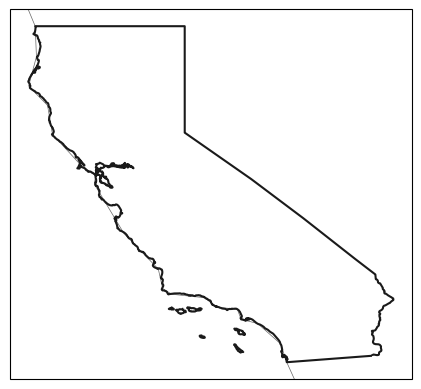

In [11]:
#regionmask.defined_regions.natural_earth.countries_110[country].plot(add_label=False)
#regionmask.defined_regions.natural_earth_v5_0_0.countries_110[country].plot(add_label=False)
regionmask.defined_regions.natural_earth_v5_0_0.us_states_10[admin].plot(add_label=False)
regionmask.defined_regions.natural_earth_v5_0_0.us_states_10[admin]

### Read landmask

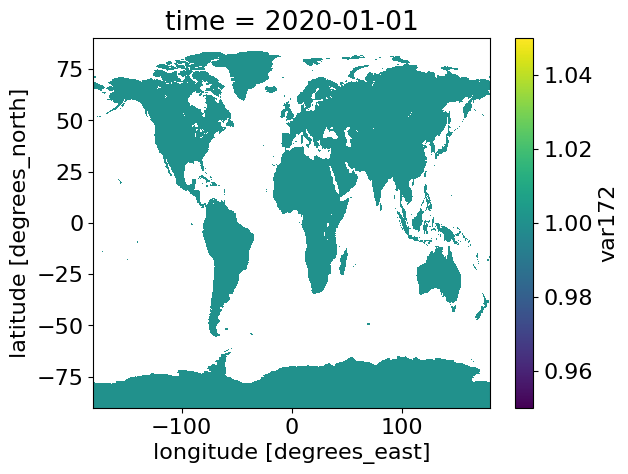

In [12]:
# read landmasks
varname       = "var172"
# binary mask (0/1)
ifile_name    = "landmask_era5_global.nc"
ifile         = os.path.join("/home/nejk/code/drought_on_demand/masks", ifile_name)
landmask_ecm = xr.open_dataset(ifile)[varname]
landmask_ecm = landmask_ecm.where( landmask_ecm.values == 1 )
landmask_ecm.plot()
nc_f = nc4.Dataset(ifile)
lats = np.asarray(nc_f["lat"][:])
lons = np.asarray(nc_f["lon"][:])
grid_lon, grid_lat = np.meshgrid(lons, lats)

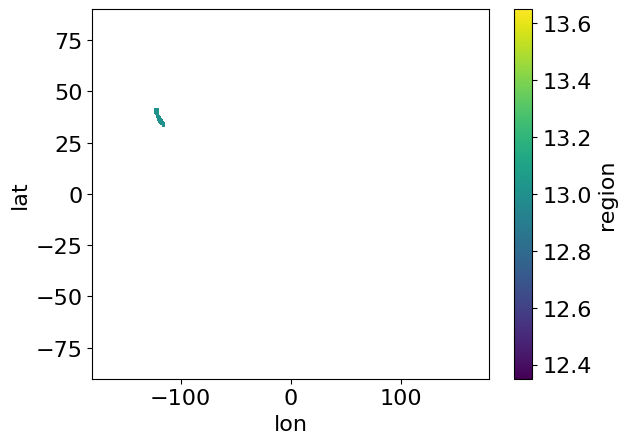

In [13]:
# mask country data
#gpoints = grid2df(grid_lon, grid_lat, ret='gpd', crs='epsg:4326')
#mask    = mask_gridpoints_in_polygon(gpoints, countryshp, return_shape=grid_lon.shape, crs='epsg:4326')
# mask country data -now using regionmask
#mask = regionmask.defined_regions.natural_earth.countries_110[country].mask(lons, lats)
#mask = regionmask.defined_regions.natural_earth_v5_0_0.countries_110[country].mask(lons, lats)
mask = regionmask.defined_regions.natural_earth_v5_0_0.us_states_10[admin].mask(lons, lats)
mask.plot()

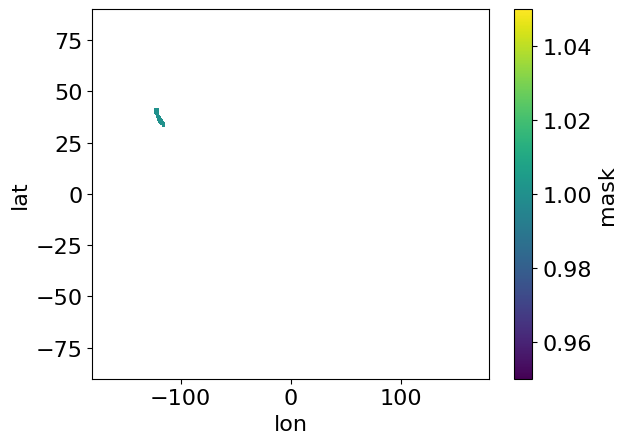

In [14]:
# set mask values to np.nan / 1
mask = xr.where(np.isnan(mask), np.nan, 1)
mask.plot()

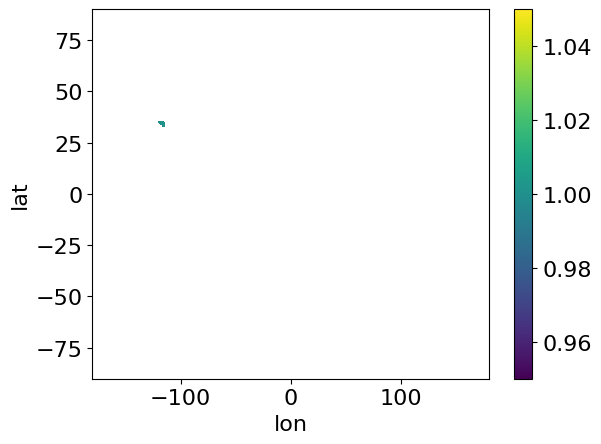

In [16]:
mask = xr.where(mask.lat >= 35.75, np.nan, mask)
mask.plot()

## Reanalysis data

### Read P-PET data

In [17]:
if drought_index == "SPEI":
    ifile_name    = "grib_files/wb_all.nc"
    ifile         = os.path.join(ipath, ifile_name)
    pmpet         = xr.open_dataset(ifile)
    print(pmpet)

<xarray.Dataset> Size: 4GB
Dimensions:  (time: 1020, lon: 1440, lat: 721)
Coordinates:
  * time     (time) datetime64[ns] 8kB 1940-01-01T06:00:00 ... 2024-12-01T06:...
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
Data variables:
    wb       (time, lat, lon) float32 4GB ...
Attributes:
    CDI:          Climate Data Interface version 2.4.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Thu Jan 23 14:12:26 2025: cdo -expr,wb=tp-pev -merge precip...
    CDO:          Climate Data Operators version 2.4.0 (https://mpimet.mpg.de...


In [18]:
if drought_index == "SPEI":
    #pmpet_country= mask_3darray(pmpet, mask, maskval=1, fillval=np.nan)
    pmpet_country = pmpet.where(mask)

    print(pmpet_country)

<xarray.Dataset> Size: 4GB
Dimensions:  (time: 1020, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 8kB 1940-01-01T06:00:00 ... 2024-12-01T06:...
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
Data variables:
    wb       (time, lat, lon) float32 4GB 0.4425 0.4425 ... 0.01536 0.01536
Attributes:
    CDI:          Climate Data Interface version 2.4.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Thu Jan 23 14:12:26 2025: cdo -expr,wb=tp-pev -merge precip...
    CDO:          Climate Data Operators version 2.4.0 (https://mpimet.mpg.de...


## Country-based drought indicators

140323.63121050035


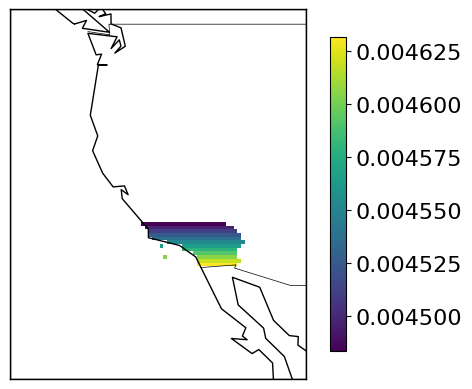

In [19]:
# Use regionmask's weights instead of calculating areas etc
weights = np.cos(np.deg2rad(lats))
#print(weights)

# old school

EARTHRADIUS = 6371  # earth radius [km]
def calculate_gridarea(lats_centr, res, nlon):
    ## make use of numpy vectorization
    lats1 = (lats_centr + (res / 2)) * np.pi / 180  # np.sin requires radians
    lats2 = (lats_centr - (res / 2)) * np.pi / 180
    areas = (
        (np.pi / 180) * (EARTHRADIUS ** 2) * np.abs(np.sin(lats1) - np.sin(lats2)) * res
    )

    ## overwrite any areas of 0 (at the poles) with np.NaN to prevent problems
    areas[np.where(areas == 0.0)] = np.NaN  # only works for arrays
    # return array of dimension nlat x nlon
    area_2d = np.swapaxes(np.tile(areas, (nlon, 1)), 0, 1)
    return area_2d

area_2d = calculate_gridarea(lats, res=abs(lats[1]-lats[0]), nlon=len(lons))  
country_area_2d = mask.values * area_2d
country_area_2d[country_area_2d==0] = np.nan
country_area_total = np.nansum(country_area_2d)
if debug:
    print(country_area_total)
country_area_weights = country_area_2d/country_area_total

if debug:
    fig = plt.figure()
    m = Basemap(projection='cyl', llcrnrlon=-180, \
            urcrnrlon=180.,llcrnrlat=grid_lat.min(),urcrnrlat=grid_lat.max(), \
            resolution='c')
    x, y = m(grid_lon, grid_lat)
    m.drawcoastlines()
    m.drawmapboundary()
    m.drawcountries()
    plt.xlim((-130,-110))
    plt.ylim((25,50))
    ax1 = m.pcolormesh(x, y, country_area_weights, shading='auto')
    plt.colorbar(ax1, orientation='vertical', shrink=0.85)
    plt.show()

### Calulate average P-PET

1020
(1020,)
1020


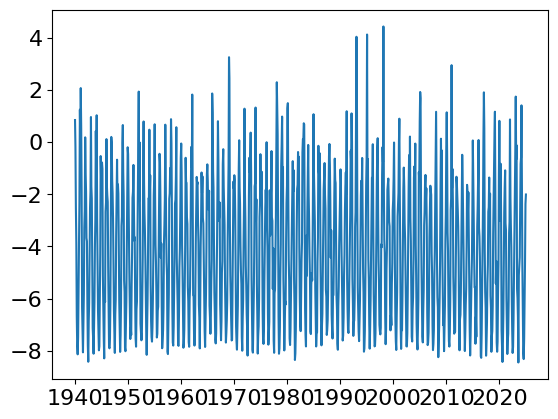

In [20]:
if drought_index == "SPEI":
    print(pmpet_country['wb'].shape[0])
    pmpet_country_ts = np.zeros(pmpet_country['wb'].shape[0])
    
    for it in range(len(pmpet_country_ts)):
        #print(type(pmpet_country['wb'].isel(time=it)))
        #pmpet_country_ts[it] = pmpet_country['wb'].isel(time=it).weighted(weights).mean(dim=("lat", "lon")) # not working yet
        pmpet_country_ts[it] = np.nansum(pmpet_country['wb'].isel(time=it).values * country_area_2d / country_area_total)
    
    print(pmpet_country_ts.shape)
    print(dates.size)
    plt.figure()
    plt.plot(dates, pmpet_country_ts)
    

### Calculate drought indicator

True
True
2020
                     0
1991-01-31  -35.850519
1991-02-28  -55.609711
1991-03-31   36.751099
1991-04-30 -156.950733
1991-05-31 -199.370125
...                ...
2020-08-31 -237.386375
2020-09-30 -198.838555
2020-10-31 -145.549491
2020-11-30  -80.318203
2020-12-31  -54.702166

[360 rows x 1 columns]
Processing country average of spei1...


/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:144: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  timeseries        = np.asarray(pdata[ind_dates])
/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:145: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  timeseries_ref    = np.asarray(pdata_ref[ind_dates_ref])
/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:197: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as la

Processing country average of spei3...


/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:197: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  standardised_index[ind_dates] = ppfv
/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:144: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  timeseries        = np.asarray(pdata[ind_dates])
/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:145: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consisten

Processing country average of spei6...


/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:197: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  standardised_index[ind_dates] = ppfv
/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:144: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  timeseries        = np.asarray(pdata[ind_dates])
/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:145: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consisten

Processing country average of spei12...


/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:197: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  standardised_index[ind_dates] = ppfv
/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:144: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  timeseries        = np.asarray(pdata[ind_dates])
/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought_on_demand/drought_stripes/spidi/spidi/spidi.py:145: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consisten

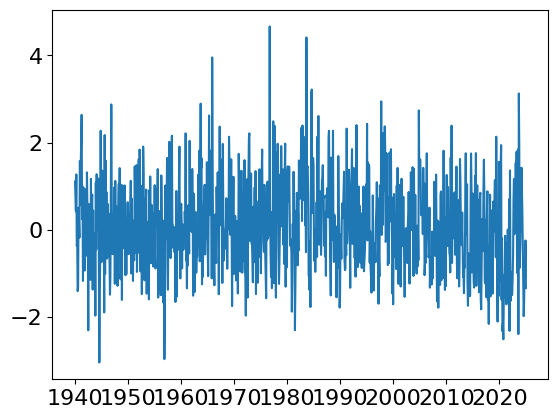

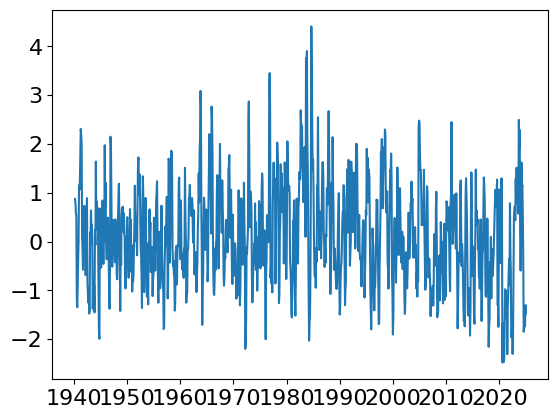

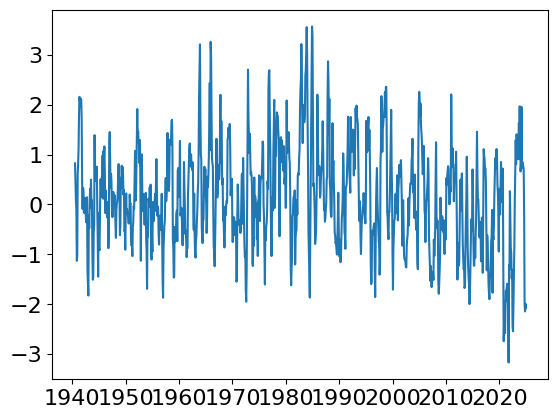

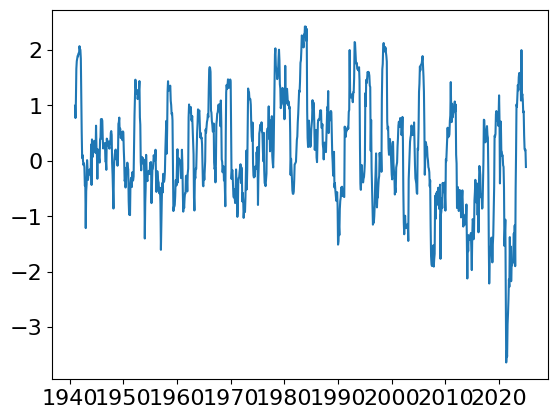

In [21]:
if drought_index == "SPEI":

    spei_country_ts = {}
        
    dfdata = pd.DataFrame(pmpet_country_ts, index=pdate_seq)
    dfdata.index = pd.to_datetime(dfdata.index)
    dfdata = convert_mmperday_to_mmpermonth(dfdata, list(dfdata.columns.values))
    dfdata_ref = dfdata.iloc[ (dfdata.index.year >= ryyyy_start) & (dfdata.index.year <= ryyyy_end) ]
    
    print((dfdata.index.year >= ryyyy_start).any())
    print((dfdata.index.year <= ryyyy_end).any())
    print(ryyyy_end)
    print((dfdata_ref))
    
    for window in windows:
        print(f"Processing country average of {drought_index.lower()}{window}...")
    
        tspi_country = calculate_si(dfdata, dfdata_ref = dfdata_ref, window = window, distribution = 'genlogistic', integration_frequency_string = '%m-%d',
            n_events_min = 5, max_zeros = 0.99, remove_zeros = False, pzero_replace = False, pzero_center_mass = False)[f"si{window}_0"]
        
        # write to dictionary
        ivar      = f"{drought_index.lower()}{window}"
        spei_country_ts[ivar] = tspi_country.values[:]
        del(tspi_country)
    
        plt.figure()
        plt.plot(dates, spei_country_ts[ivar])

## Plots...

### Normal SPI/SPEI plot

1
2020-01-31 00:00:00
3
2020-03-31 00:00:00
6
2020-06-30 00:00:00
12
2020-12-31 00:00:00


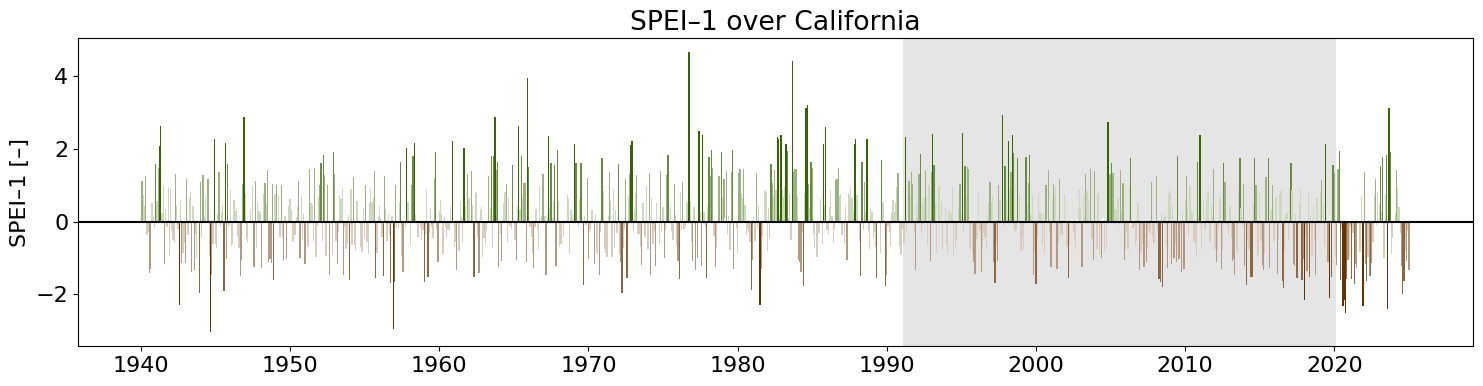

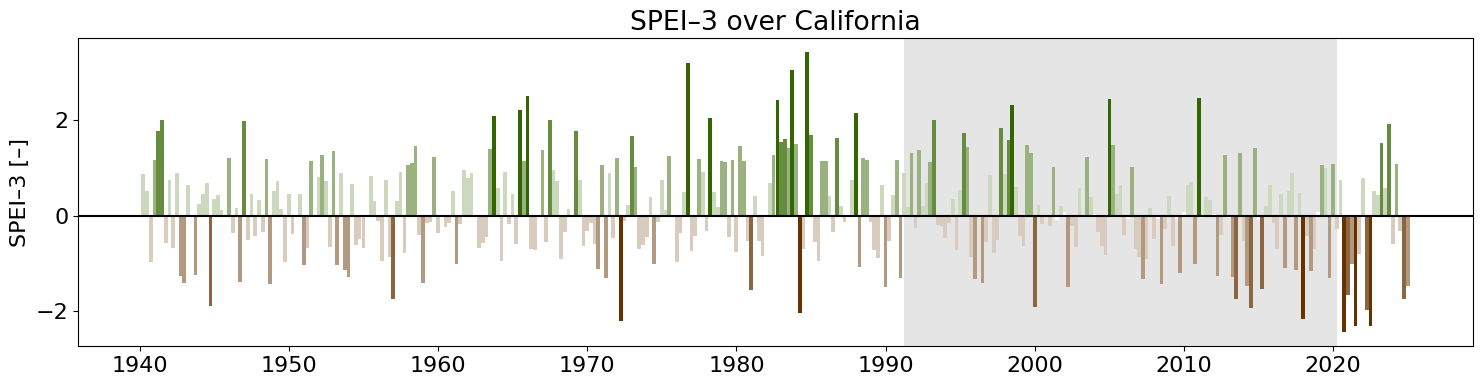

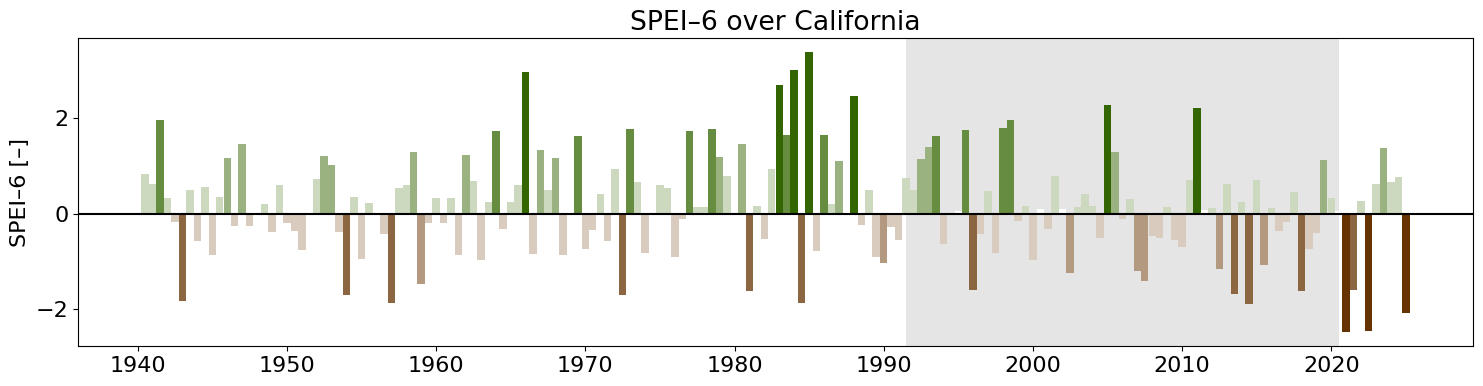

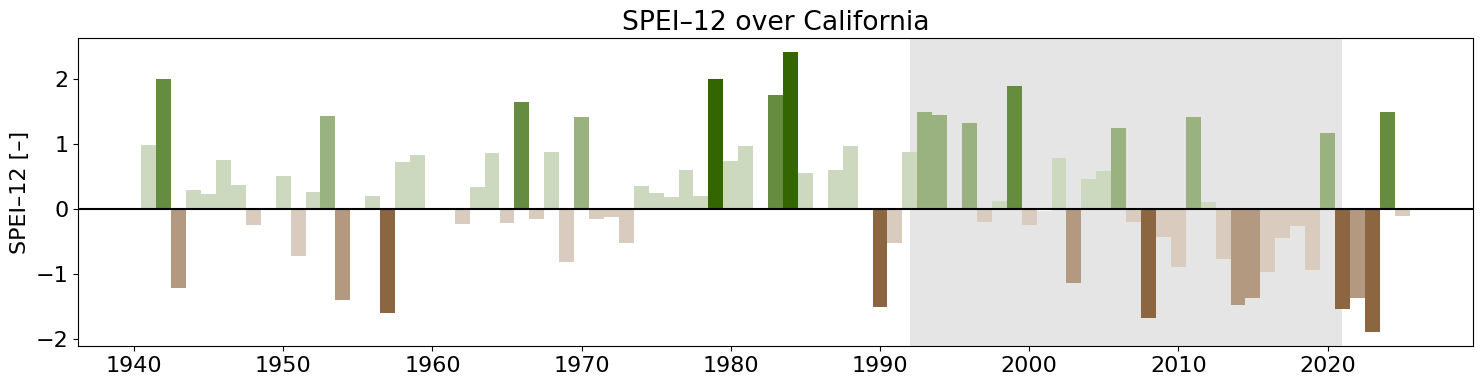

In [22]:
for window in windows:

    print(window)
    ivar      = f"{drought_index.lower()}{window}"

    plt.figure(figsize=(18,4))
    x = dates[(window-1)::window]
    #print(x)
    xyear = [ix.year for ix in x]
    #print(xyear)
    if drought_index == "SPEI":
        y = list(spei_country_ts[ivar][(window-1)::window])
        
    # color for each spi time step, including mild categories and white between -0.1 and 0.1
    y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<=-0.1: color_list[3], -0.1<p<0.1: color_list[4], 0.1<=p<1: color_list[5], 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    # color for each spi time step, excluding mild categories and grey between -1 and 1
    #y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<1: '#7F7F7F', 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    plt.bar(x, y, color=y_colors, align='center', width=365/(12/window))
    print(x[xyear.index(ryyyy_end)])
    plt.axvspan(x[xyear.index(ryyyy_start)], x[xyear.index(ryyyy_end)], facecolor='#CCCCCC', alpha=0.5)
    plt.bar(x, y, color=y_colors, align='center', width=365/(12/window))
    plt.axhline(y=0, color = 'black', linestyle = '-')
    #plt.xlabel("Date")
    plt.ylabel(f"{drought_index}–{window} [–]")
    plt.title(f"{drought_index}–{window} over {admin_name}")

    # custom legend
    from matplotlib.lines import Line2D
    custom_lines = [Line2D([0], [0], color=color_list[0], lw=4),
                    Line2D([0], [0], color=color_list[1], lw=4),
                    Line2D([0], [0], color=color_list[2], lw=4),
                    #Line2D([0], [0], color=color_list[3], lw=4),
                    Line2D([0], [0], color='#7F7F7F', lw=4),
                    #Line2D([0], [0], color=color_list[5], lw=4),
                    Line2D([0], [0], color=color_list[6], lw=4),
                    Line2D([0], [0], color=color_list[7], lw=4),
                    Line2D([0], [0], color=color_list[8], lw=4)]

    #plt.legend(custom_lines, ['extremely dry', 'severely dry', 'moderately dry','near-normal','moderately wet','severely wet','extremely wet'], ncol=7, loc='upper center')
    #print(y)
        
    del(x)
    del(y)
    del(y_colors)

### Drought Stripes

/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI1.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI1.pdf
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI3.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI3.pdf
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI6.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI6.pdf
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI12.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI12.pdf


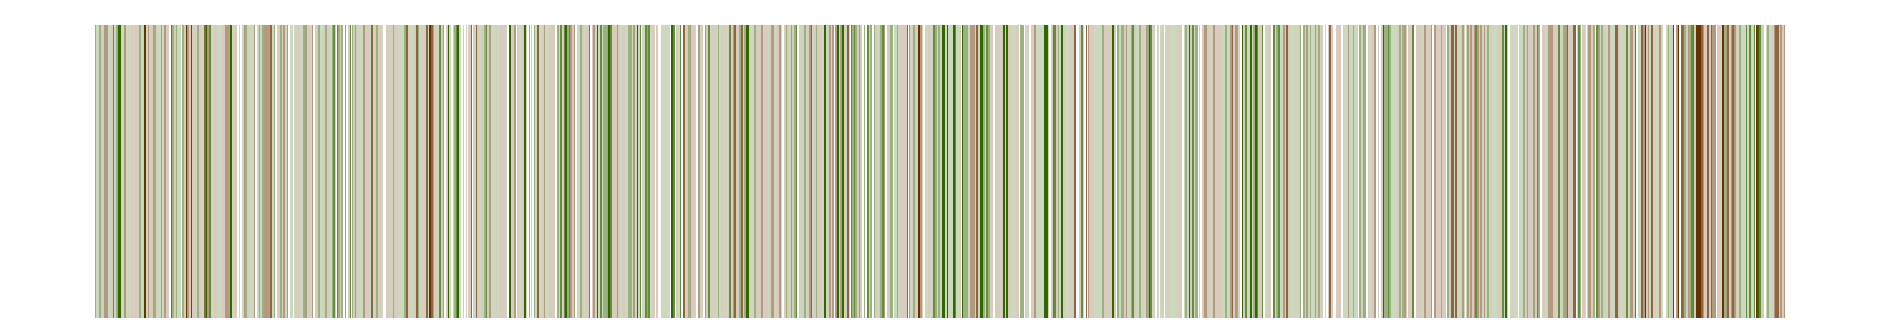

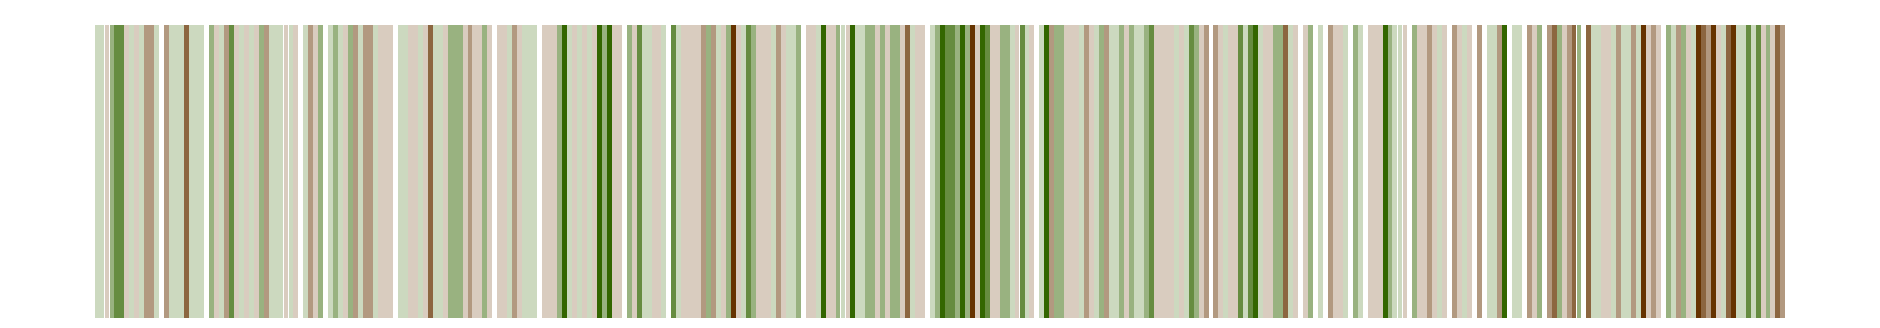

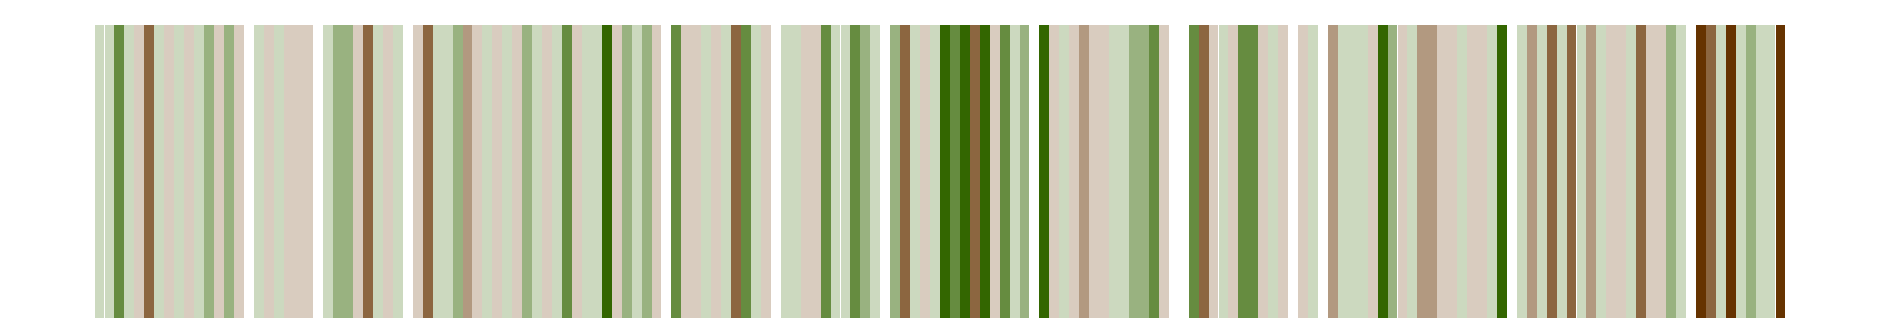

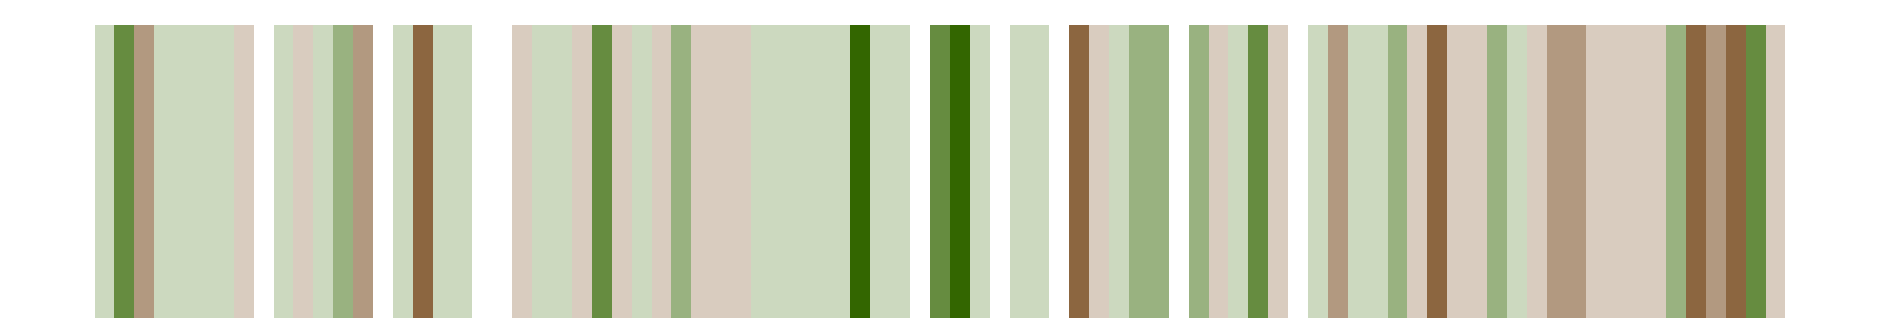

In [24]:
#os.chdir("/home/nejk/code/drought_on_demand")
for window in windows:
    plt.figure(figsize=(24,4))
    plt.axis('off')
    x = dates[(window-1)::window]
    xyear = [ix.year for ix in x]
    if drought_index == "SPI":
        y = list(spi_country_ts[f"{drought_index.lower()}{window}"][(window-1)::window])
    if drought_index == "SPEI":
        y = list(spei_country_ts[f"{drought_index.lower()}{window}"][(window-1)::window])
        
    # color for each spi time step, including mild categories and white between -0.1 and 0.1
    y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<=-0.1: color_list[3], -0.1<p<0.1: color_list[4], 0.1<=p<1: color_list[5], 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    # color for each spi time step, excluding mild categories and grey between -1 and 1
    #y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<1: '#7F7F7F', 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    plt.bar(x, np.repeat(1, len(x)), color=y_colors, align='center', width=365/(12/window))
    #fig.axes.get_xaxis().set_visible(False)
    #fig.axes.get_yaxis().set_visible(False)
    plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}.png", facecolor="white",  edgecolor='none')
    plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}.pdf", facecolor="white",  edgecolor='none')
    print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}.png")
    print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}.pdf")

983
Processing from 2021-12-31 00:00:00 to 2024-12-31 00:00:00
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI1_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI1_latest.pdf
327
Processing from 2021-12-31 00:00:00 to 2024-12-31 00:00:00
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI3_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI3_latest.pdf
163
Processing from 2021-12-31 00:00:00 to 2024-12-31 00:00:00
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI6_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI6_latest.pdf
81
Processing from 2021-12-31 00:00:00 to 2024-12-31 00:00:00
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI12_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI12_latest

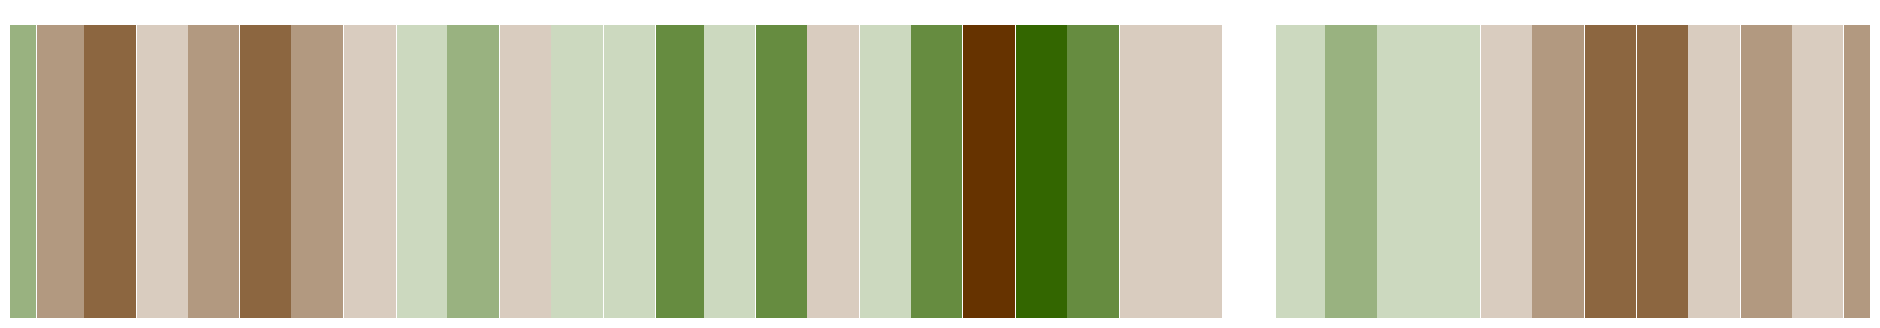

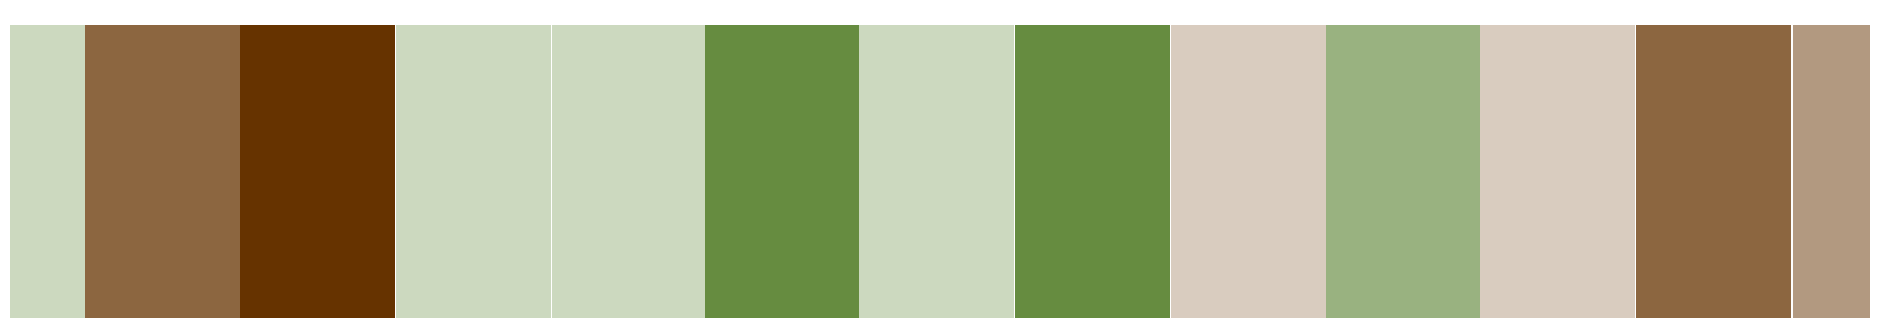

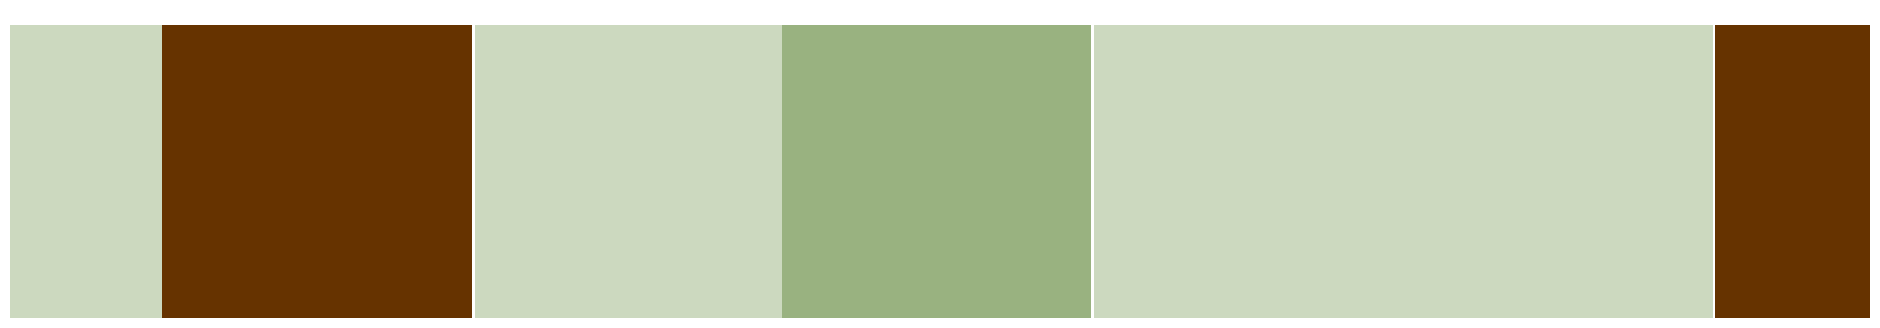

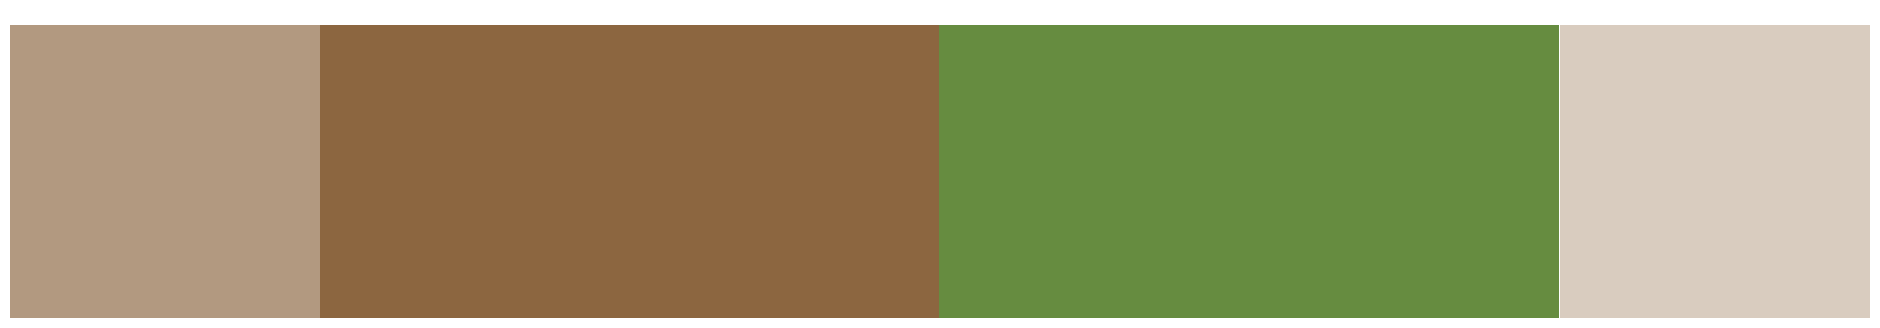

In [25]:
#os.chdir("/home/nejk/code/drought_on_demand")
for window in windows:
    plt.figure(figsize=(24,4))
    plt.axis('off')
    x = dates[(window-1)::window]
    istart = np.where(x.year == 2020)[0][-1]+int(12/window)
    print(istart)
    print(f"Processing from {x[istart]} to {x[-1]}")
    #print(f"Processing from {x[int((12/window)*istart-(12/window))]} to {x[-1]}")
    xyear = [ix.year for ix in x]
    if drought_index == "SPI":
        y = list(spi_country_ts[f"{drought_index.lower()}{window}"][(window-1)::window])
    if drought_index == "SPEI":
        y = list(spei_country_ts[f"{drought_index.lower()}{window}"][(window-1)::window])
        
    # color for each spi time step, including mild categories and white between -0.1 and 0.1
    y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<=-0.1: color_list[3], -0.1<p<0.1: color_list[4], 0.1<=p<1: color_list[5], 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    # color for each spi time step, excluding mild categories and grey between -1 and 1
    #y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<1: '#7F7F7F', 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    plt.bar(x, np.repeat(1, len(x)), color=y_colors, align='center', width=365/(12/window))
    plt.xlim(x[istart],x[-1])
    #plt.xlim(x[int((12/window)*istart-(12/window))],x[-1])
    #fig.axes.get_xaxis().set_visible(False)
    #fig.axes.get_yaxis().set_visible(False)
    plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_latest.png", facecolor="white",  edgecolor='none')
    plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_latest.pdf", facecolor="white",  edgecolor='none')
    print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_latest.png")
    print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_latest.pdf")

### MONTHLY PLOTS

984
Processing from 2022-01-31 00:00:00 to 2024-12-31 00:00:00
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI1_monthly_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI1_monthly_latest.pdf
984
Processing from 2022-01-31 00:00:00 to 2024-12-31 00:00:00
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI3_monthly_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI3_monthly_latest.pdf
984
Processing from 2022-01-31 00:00:00 to 2024-12-31 00:00:00
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI6_monthly_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI6_monthly_latest.pdf
984
Processing from 2022-01-31 00:00:00 to 2024-12-31 00:00:00
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI12_monthly_latest.png
/home/nejk/code/drought_on_demand

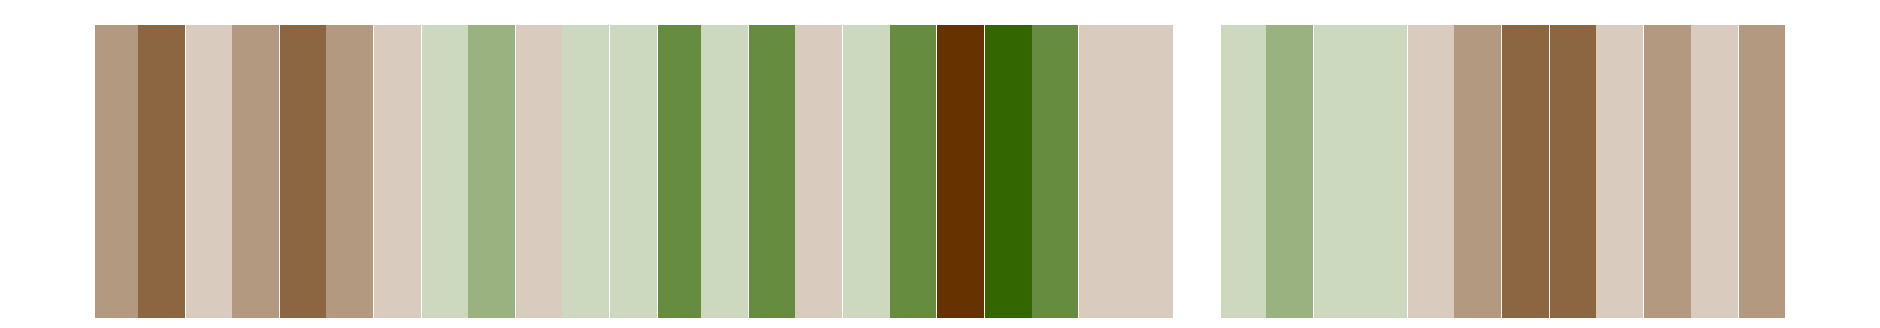

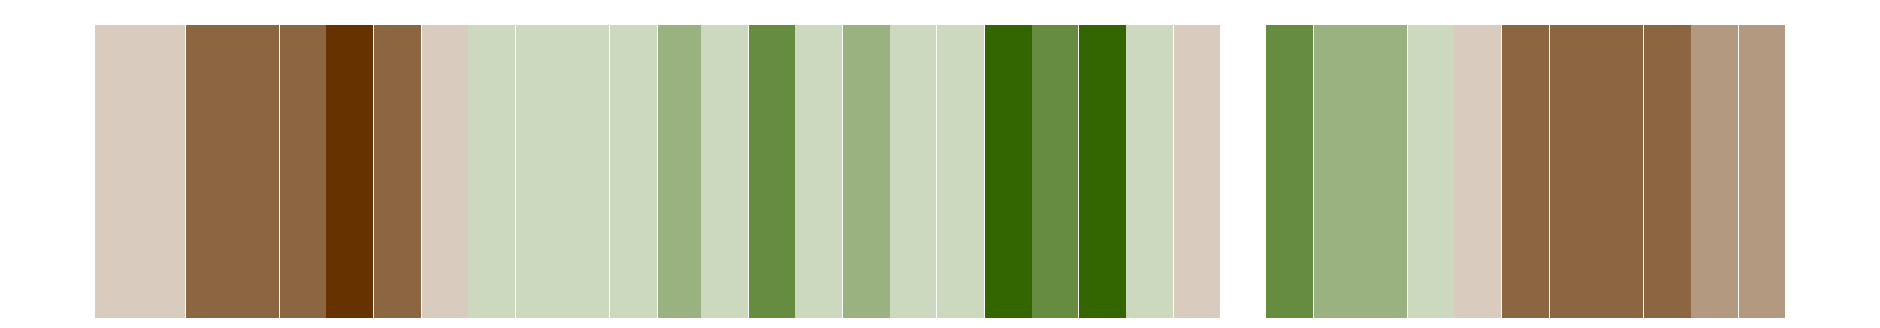

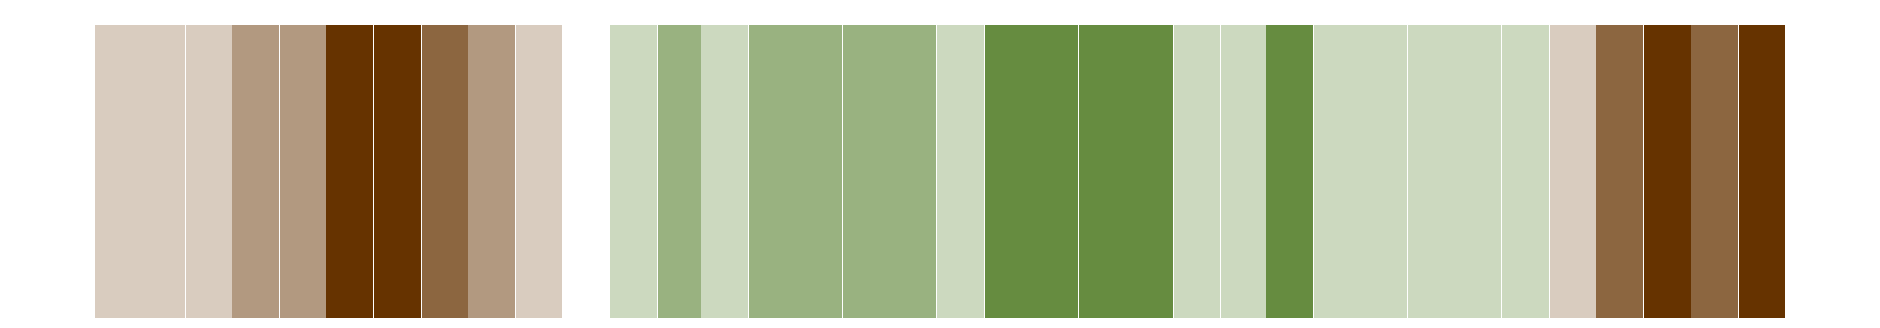

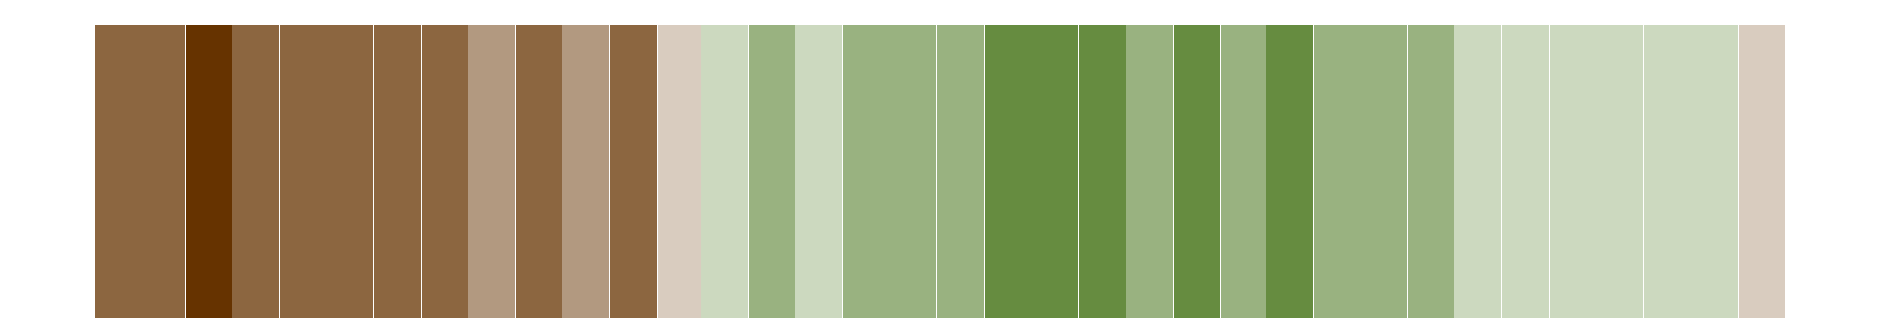

In [39]:
#os.chdir("/home/nejk/code/drought_on_demand")
for window in windows:
    plt.figure(figsize=(24,4))
    plt.axis('off')
    
    istart = np.where(dates.year == 2022)[0][0]
    print(istart)
    x = dates[istart:]
    print(f"Processing from {x[0]} to {x[-1]}")
    xyear = [ix.year for ix in x]
    
    if drought_index == "SPI":
        y = list(spi_country_ts[f"{drought_index.lower()}{window}"][istart:])
    if drought_index == "SPEI":
        y = list(spei_country_ts[f"{drought_index.lower()}{window}"][istart:])
        
    # color for each spi time step, including mild categories and white between -0.1 and 0.1
    y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<=-0.1: color_list[3], -0.1<p<0.1: color_list[4], 0.1<=p<1: color_list[5], 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    # color for each spi time step, excluding mild categories and grey between -1 and 1
    #y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<1: '#7F7F7F', 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    plt.bar(x, np.repeat(1, len(x)), color=y_colors, align='center', width=365/(12))
    #plt.xlim(x[istart],x[-1])
    #plt.xlim(x[int((12/window)*istart-(12/window))],x[-1])
    #fig.axes.get_xaxis().set_visible(False)
    #fig.axes.get_yaxis().set_visible(False)
    plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_latest.png", facecolor="white",  edgecolor='none')
    plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_latest.pdf", facecolor="white",  edgecolor='none')
    print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_latest.png")
    print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_latest.pdf")

1
985
Processing from 2022-01-31 00:00:00 to 2024-11-30 00:00:00


/etc/ecmwf/ssd/ssd1/ecinteractive/nejk-ecinteractive/tmpdirs/nejk.20406252/ipykernel_1596727/1505807880.py:8: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  shifted_dates = pd.date_range(start="1939-12-15",end="2024-12-15", freq='M')


/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI1_monthly_classical_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI1_monthly_classical_latest.pdf
3
985
Processing from 2022-01-31 00:00:00 to 2024-11-30 00:00:00


/etc/ecmwf/ssd/ssd1/ecinteractive/nejk-ecinteractive/tmpdirs/nejk.20406252/ipykernel_1596727/1505807880.py:8: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  shifted_dates = pd.date_range(start="1939-12-15",end="2024-12-15", freq='M')


/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI3_monthly_classical_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI3_monthly_classical_latest.pdf
6
985
Processing from 2022-01-31 00:00:00 to 2024-11-30 00:00:00


/etc/ecmwf/ssd/ssd1/ecinteractive/nejk-ecinteractive/tmpdirs/nejk.20406252/ipykernel_1596727/1505807880.py:8: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  shifted_dates = pd.date_range(start="1939-12-15",end="2024-12-15", freq='M')


/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI6_monthly_classical_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI6_monthly_classical_latest.pdf
12
985
Processing from 2022-01-31 00:00:00 to 2024-11-30 00:00:00


/etc/ecmwf/ssd/ssd1/ecinteractive/nejk-ecinteractive/tmpdirs/nejk.20406252/ipykernel_1596727/1505807880.py:8: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  shifted_dates = pd.date_range(start="1939-12-15",end="2024-12-15", freq='M')


/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI12_monthly_classical_latest.png
/home/nejk/code/drought_on_demand/drought_stripes/figures/SouthernCalifornia_SPEI12_monthly_classical_latest.pdf


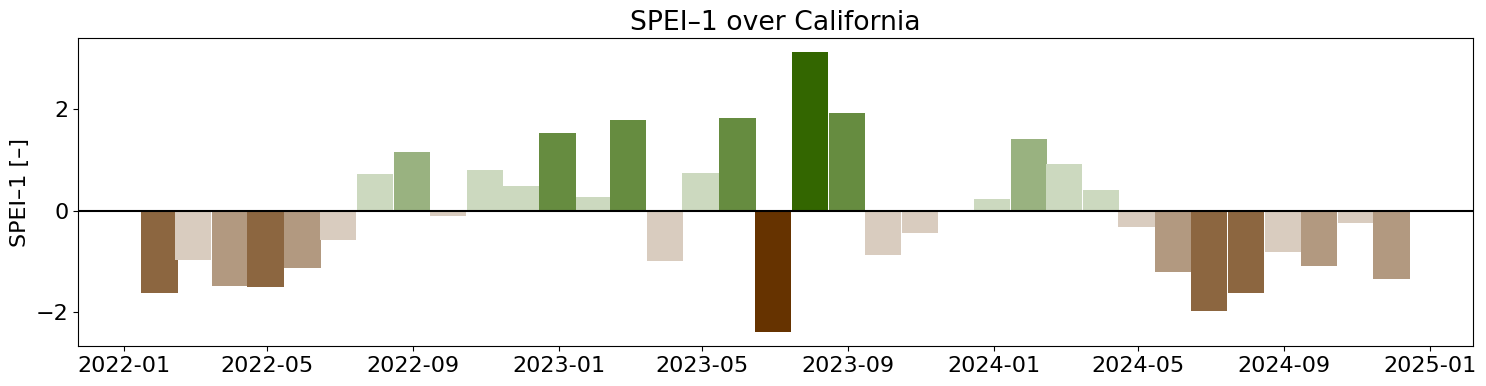

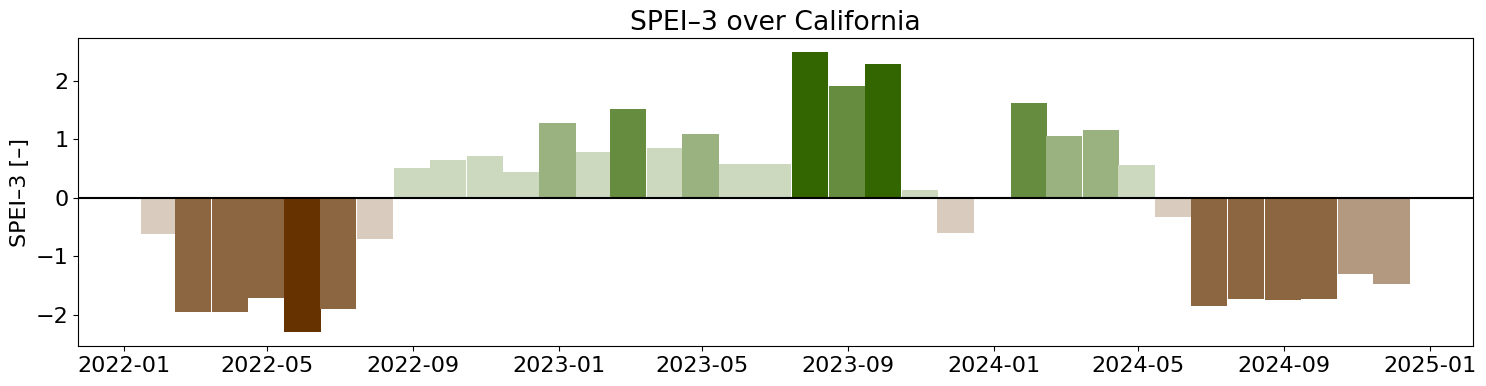

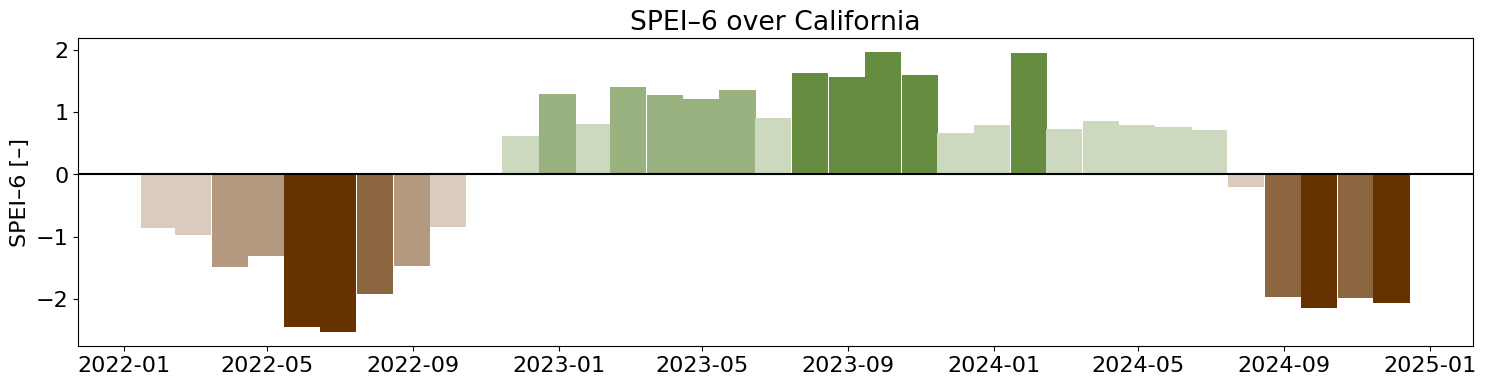

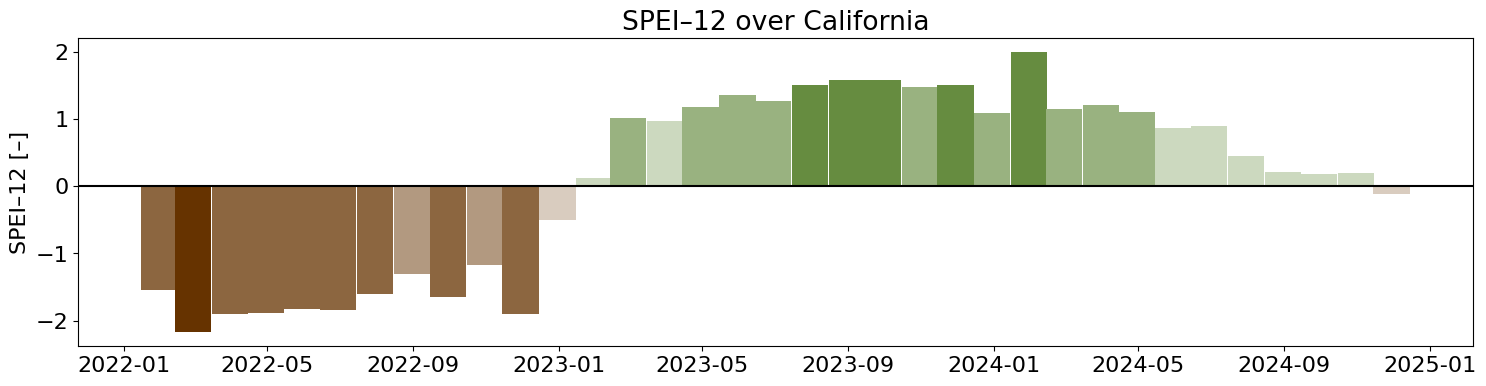

In [44]:
for window in windows:

    print(window)
    ivar      = f"{drought_index.lower()}{window}"

    plt.figure(figsize=(18,4))
    
    istart = np.where(shifted_dates.year == 2022)[0][0]
    print(istart)

    x = dates[istart:]
    print(f"Processing from {x[0]} to {x[-1]}")
    xyear = [ix.year for ix in x]
    
    if drought_index == "SPI":
        y = list(spi_country_ts[f"{drought_index.lower()}{window}"][istart:])
    if drought_index == "SPEI":
        y = list(spei_country_ts[f"{drought_index.lower()}{window}"][istart:])
        
    # color for each spi time step, including mild categories and white between -0.1 and 0.1
    y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<=-0.1: color_list[3], -0.1<p<0.1: color_list[4], 0.1<=p<1: color_list[5], 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    # color for each spi time step, excluding mild categories and grey between -1 and 1
    #y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<1: '#7F7F7F', 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    plt.bar(x, y, color=y_colors, align='center', width=365/(12))
    #print(x[xyear.index(ryyyy_end)])
    #plt.axvspan(x[xyear.index(ryyyy_start)], x[xyear.index(ryyyy_end)], facecolor='#CCCCCC', alpha=0.5)
    plt.bar(x, y, color=y_colors, align='center', width=365/(12))
    plt.axhline(y=0, color = 'black', linestyle = '-')
    #plt.xlabel("Date")
    plt.ylabel(f"{drought_index}–{window} [–]")
    plt.title(f"{drought_index}–{window} over {admin_name}")
    
    #plt.xlim(x[istart],x[-1])

    # custom legend
    from matplotlib.lines import Line2D
    custom_lines = [Line2D([0], [0], color=color_list[0], lw=4),
                    Line2D([0], [0], color=color_list[1], lw=4),
                    Line2D([0], [0], color=color_list[2], lw=4),
                    #Line2D([0], [0], color=color_list[3], lw=4),
                    Line2D([0], [0], color='#7F7F7F', lw=4),
                    #Line2D([0], [0], color=color_list[5], lw=4),
                    Line2D([0], [0], color=color_list[6], lw=4),
                    Line2D([0], [0], color=color_list[7], lw=4),
                    Line2D([0], [0], color=color_list[8], lw=4)]

    #plt.legend(custom_lines, ['extremely dry', 'severely dry', 'moderately dry','near-normal','moderately wet','severely wet','extremely wet'], ncol=7, loc='upper center')
    #print(y)
        
    del(x)
    del(y)
    del(y_colors)

    plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.png", facecolor="white",  edgecolor='none')
    plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.pdf", facecolor="white",  edgecolor='none')
    print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.png")
    print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.pdf")